# 3. Univariate and bivariate analysis

Review numeric and categorical distributions, then compare survival by sex, passenger class, and fare. Bar heights for survival comparisons represent observed proportions.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import seaborn as sns
from src.data_loader import load_data

df = load_data()
sns.set_theme(style="whitegrid")

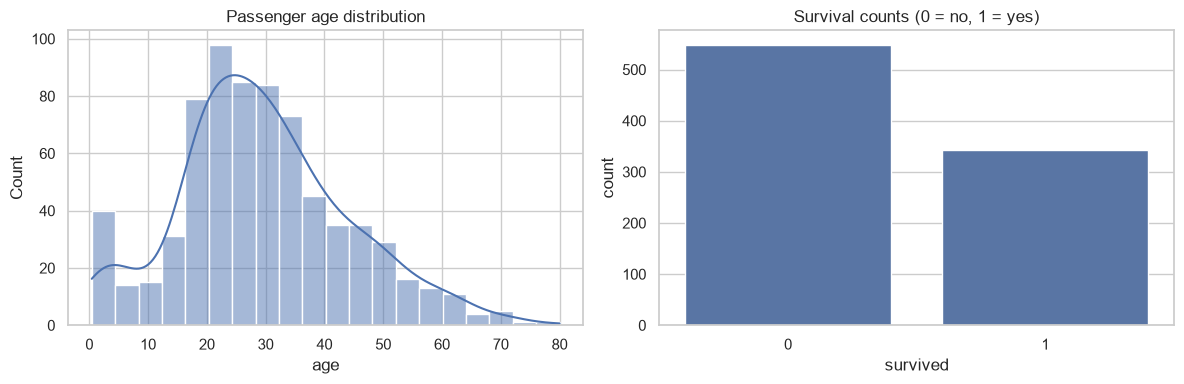

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="age", kde=True, ax=axes[0])
sns.countplot(data=df, x="survived", ax=axes[1])
axes[0].set_title("Passenger age distribution")
axes[1].set_title("Survival counts (0 = no, 1 = yes)")
plt.tight_layout()

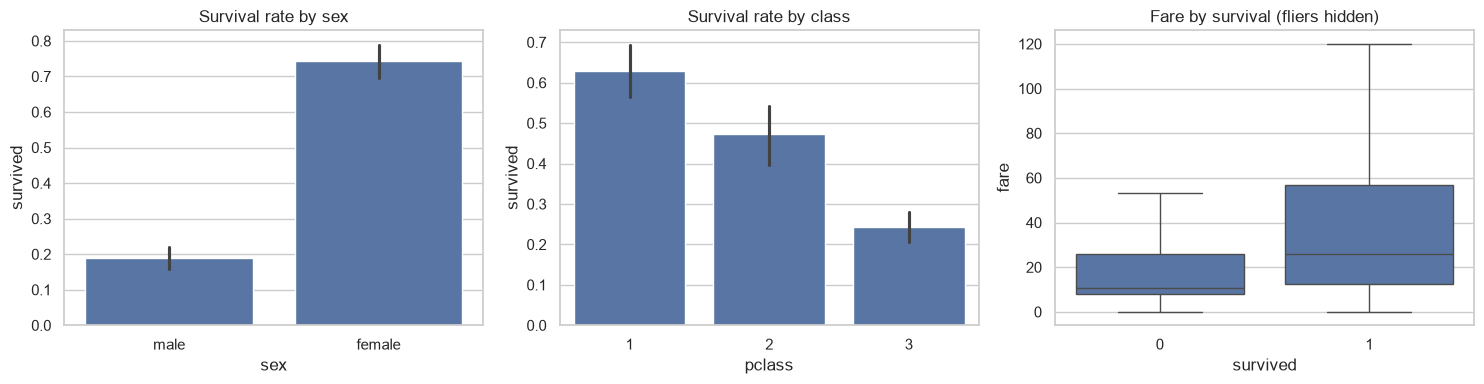

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=df, x="sex", y="survived", errorbar=("ci", 95), ax=axes[0])
sns.barplot(data=df, x="pclass", y="survived", errorbar=("ci", 95), ax=axes[1])
sns.boxplot(data=df, x="survived", y="fare", showfliers=False, ax=axes[2])
axes[0].set_title("Survival rate by sex")
axes[1].set_title("Survival rate by class")
axes[2].set_title("Fare by survival (fliers hidden)")
plt.tight_layout()

In [4]:
display(df.groupby(["sex", "pclass"], observed=True)["survived"].agg(["mean", "count"]))
display(df.groupby("survived", observed=True)[["age", "fare", "sibsp", "parch"]].median())

mean  count
sex    pclass                 
female 1       0.968085     94
       2       0.921053     76
       3       0.500000    144
male   1       0.368852    122
       2       0.157407    108
       3       0.135447    347

,age,fare,sibsp,parch
survived,,,,
0,28.0,10.5,0.0,0.0
1,28.0,26.0,0.0,0.0
